<a href="https://colab.research.google.com/github/adityasptra14/subscription-churn-sql-analysis/blob/main/Subscription_Churn_SQL_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid")
np.random.seed(101)

# 1. Membuat koneksi database SQL di Google Colab
conn = sqlite3.connect('telecom_subscription.db')
cursor = conn.cursor()

# 2. Membuat data simulasi 3.000 pelanggan
n_cust = 3000
cust_ids = [f'USR-{20000 + i}' for i in range(n_cust)]

df_customers = pd.DataFrame({
    'customer_id': cust_ids,
    'age_group': np.random.choice(['18-24', '25-34', '35-44', '45+'], size=n_cust, p=[0.25, 0.40, 0.20, 0.15]),
    'city_tier': np.random.choice(['Tier 1 (Metropolitan)', 'Tier 2 (Kota Besar)', 'Tier 3 (Daerah)'], size=n_cust, p=[0.5, 0.3, 0.2])
})

# Membuat data langganan (Kontrak bulanan memiliki risiko churn lebih tinggi dibanding tahunan)
contract_types = np.random.choice(['Monthly (Bulanan)', '1-Year (Tahunan)', '2-Year (2 Tahun)'], size=n_cust, p=[0.55, 0.30, 0.15])
plan_types = np.random.choice(['Basic', 'Standard HD', 'Premium Ultra'], size=n_cust, p=[0.40, 0.35, 0.25])
payment_methods = np.random.choice(['E-Wallet', 'Virtual Account / Transfer', 'Credit Card / Auto-Debit'], size=n_cust, p=[0.45, 0.30, 0.25])

price_map = {'Basic': 65000, 'Standard HD': 120000, 'Premium Ultra': 185000}
monthly_charges = [price_map[p] for p in plan_types]
tenure_months = np.random.randint(1, 36, size=n_cust)

# Logika probabilitas churn yang realistis
churn_prob = []
for c, t, pay in zip(contract_types, tenure_months, payment_methods):
    p = 0.08
    if c == 'Monthly (Bulanan)': p += 0.25
    if t <= 3: p += 0.22
    elif t <= 6: p += 0.10
    if pay == 'Virtual Account / Transfer': p += 0.08
    churn_prob.append(min(p, 0.85))

is_churned = [np.random.choice([1, 0], p=[prob, 1 - prob]) for prob in churn_prob]

df_subscriptions = pd.DataFrame({
    'customer_id': cust_ids,
    'plan_type': plan_types,
    'contract_type': contract_types,
    'payment_method': payment_methods,
    'tenure_months': tenure_months,
    'monthly_charge': monthly_charges,
    'churn_status': is_churned
})

# Membuat tabel tiket keluhan pelanggan
df_tickets = pd.DataFrame({
    'customer_id': cust_ids,
    'ticket_count': [np.random.choice([0, 1, 2, 3, 4, 5], p=[0.5, 0.25, 0.12, 0.07, 0.04, 0.02]) if ch == 0
                     else np.random.choice([0, 1, 2, 3, 4, 5], p=[0.15, 0.20, 0.25, 0.20, 0.12, 0.08]) for ch in is_churned],
    'avg_resolution_hours': np.round(np.random.uniform(2, 48, size=n_cust), 1)
})

# Menyimpan ketiga DataFrame ke dalam tabel SQL
df_customers.to_sql('customers', conn, if_exists='replace', index=False)
df_subscriptions.to_sql('subscriptions', conn, if_exists='replace', index=False)
df_tickets.to_sql('support_tickets', conn, if_exists='replace', index=False)

print("Database SQL berhasil dibuat! Terdapat 3 tabel: 'customers', 'subscriptions', dan 'support_tickets'.")

Database SQL berhasil dibuat! Terdapat 3 tabel: 'customers', 'subscriptions', dan 'support_tickets'.


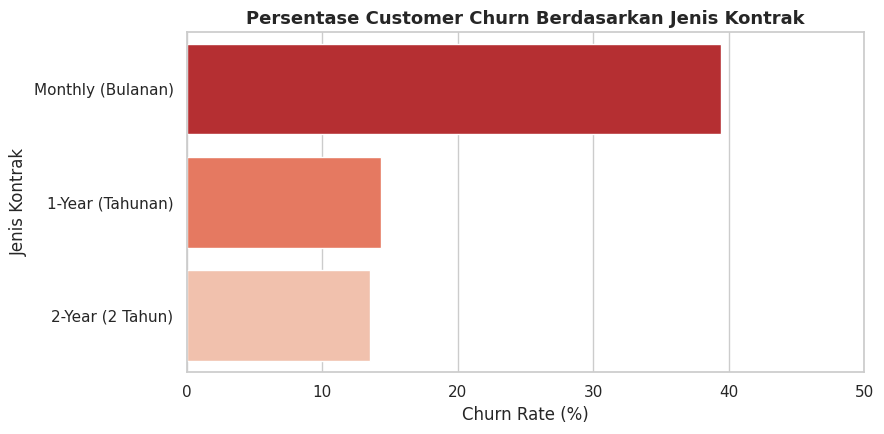

,Jenis_Kontrak,Total_Pelanggan,Pelanggan_Churn,Churn_Rate_Pct,Revenue_Lost_IDR
0,Monthly (Bulanan),1604,632,39.40,71770000
1,1-Year (Tahunan),922,132,14.32,15145000
2,2-Year (2 Tahun),474,64,13.50,7330000


In [2]:
query_contract = """
SELECT
    contract_type AS Jenis_Kontrak,
    COUNT(customer_id) AS Total_Pelanggan,
    SUM(churn_status) AS Pelanggan_Churn,
    ROUND(AVG(churn_status) * 100, 2) AS Churn_Rate_Pct,
    SUM(CASE WHEN churn_status = 1 THEN monthly_charge ELSE 0 END) AS Revenue_Lost_IDR
FROM subscriptions
GROUP BY contract_type
ORDER BY Churn_Rate_Pct DESC;
"""

df_sql_contract = pd.read_sql_query(query_contract, conn)

plt.figure(figsize=(9, 4.5))
sns.barplot(
    data=df_sql_contract,
    x='Churn_Rate_Pct',
    y='Jenis_Kontrak',
    hue='Jenis_Kontrak',
    palette='Reds_r',
    legend=False
)
plt.title('Persentase Customer Churn Berdasarkan Jenis Kontrak', fontsize=13, fontweight='bold')
plt.xlabel('Churn Rate (%)')
plt.ylabel('Jenis Kontrak')
plt.xlim(0, 50)
plt.tight_layout()
plt.savefig('churn_by_contract.png', dpi=300)
plt.show()

display(df_sql_contract)

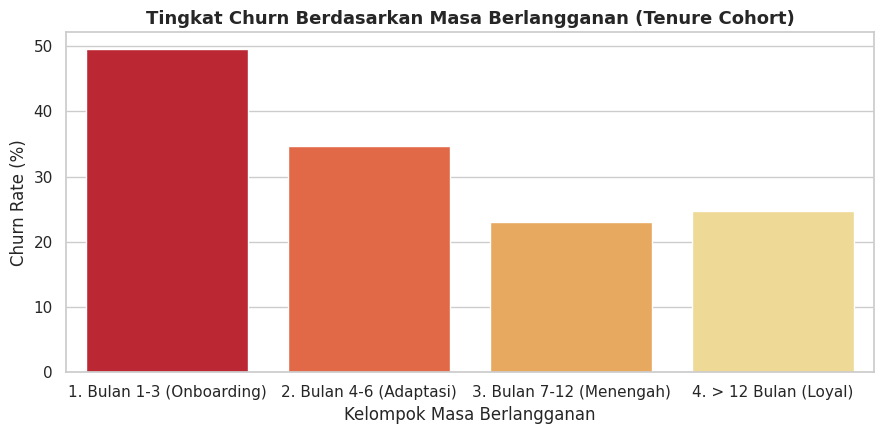

,Kelompok_Masa_Aktif,Total_Pelanggan,Jumlah_Churn,Churn_Rate_Pct,Pendapatan_Hilang
0,1. Bulan 1-3 (Onboarding),280,139,49.64,16180000
1,2. Bulan 4-6 (Adaptasi),245,85,34.69,9705000
2,3. Bulan 7-12 (Menengah),489,113,23.11,12385000
3,4. > 12 Bulan (Loyal),1986,491,24.72,55975000


In [3]:
query_tenure_cte = """
WITH Tenure_Cohort AS (
    SELECT
        customer_id,
        churn_status,
        monthly_charge,
        CASE
            WHEN tenure_months <= 3 THEN '1. Bulan 1-3 (Onboarding)'
            WHEN tenure_months BETWEEN 4 AND 6 THEN '2. Bulan 4-6 (Adaptasi)'
            WHEN tenure_months BETWEEN 7 AND 12 THEN '3. Bulan 7-12 (Menengah)'
            ELSE '4. > 12 Bulan (Loyal)'
        END AS Kelompok_Masa_Aktif
    FROM subscriptions
)
SELECT
    Kelompok_Masa_Aktif,
    COUNT(customer_id) AS Total_Pelanggan,
    SUM(churn_status) AS Jumlah_Churn,
    ROUND(AVG(churn_status) * 100, 2) AS Churn_Rate_Pct,
    SUM(CASE WHEN churn_status = 1 THEN monthly_charge ELSE 0 END) AS Pendapatan_Hilang
FROM Tenure_Cohort
GROUP BY Kelompok_Masa_Aktif
ORDER BY Kelompok_Masa_Aktif;
"""

df_sql_tenure = pd.read_sql_query(query_tenure_cte, conn)

plt.figure(figsize=(9, 4.5))
sns.barplot(
    data=df_sql_tenure,
    x='Kelompok_Masa_Aktif',
    y='Churn_Rate_Pct',
    hue='Kelompok_Masa_Aktif',
    palette='YlOrRd_r',
    legend=False
)
plt.title('Tingkat Churn Berdasarkan Masa Berlangganan (Tenure Cohort)', fontsize=13, fontweight='bold')
plt.xlabel('Kelompok Masa Berlangganan')
plt.ylabel('Churn Rate (%)')
plt.tight_layout()
plt.savefig('churn_by_tenure.png', dpi=300)
plt.show()

display(df_sql_tenure)

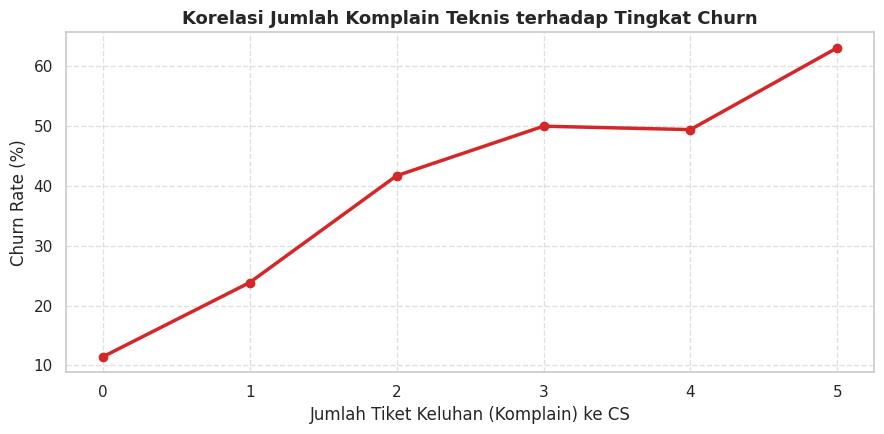

,Jumlah_Tiket_Keluhan,Total_Pelanggan,Pelanggan_Churn,Churn_Rate_Pct
0,0,1214,139,11.45
1,1,687,164,23.87
2,2,477,199,41.72
3,3,324,162,50.00
4,4,176,87,49.43
5,5,122,77,63.11


In [4]:
query_join_tickets = """
SELECT
    t.ticket_count AS Jumlah_Tiket_Keluhan,
    COUNT(s.customer_id) AS Total_Pelanggan,
    SUM(s.churn_status) AS Pelanggan_Churn,
    ROUND(AVG(s.churn_status) * 100, 2) AS Churn_Rate_Pct
FROM subscriptions s
INNER JOIN support_tickets t ON s.customer_id = t.customer_id
GROUP BY t.ticket_count
ORDER BY t.ticket_count;
"""

df_sql_tickets = pd.read_sql_query(query_join_tickets, conn)

plt.figure(figsize=(9, 4.5))
plt.plot(df_sql_tickets['Jumlah_Tiket_Keluhan'], df_sql_tickets['Churn_Rate_Pct'], marker='o', linewidth=2.5, color='#d62728')
plt.title('Korelasi Jumlah Komplain Teknis terhadap Tingkat Churn', fontsize=13, fontweight='bold')
plt.xlabel('Jumlah Tiket Keluhan (Komplain) ke CS')
plt.ylabel('Churn Rate (%)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig('churn_by_tickets.png', dpi=300)
plt.show()

display(df_sql_tickets)

In [5]:
sql_script_content = """-- =====================================================================
-- PROYEK: ANALISIS CUSTOMER CHURN & RETENSI PELANGGAN
-- Dialek: SQL (SQLite / Standard ANSI SQL)
-- =====================================================================

-- 1. Evaluasi Churn Rate dan Revenue Lost Berdasarkan Jenis Kontrak
SELECT
    contract_type AS Jenis_Kontrak,
    COUNT(customer_id) AS Total_Pelanggan,
    SUM(churn_status) AS Pelanggan_Churn,
    ROUND(AVG(churn_status) * 100, 2) AS Churn_Rate_Pct,
    SUM(CASE WHEN churn_status = 1 THEN monthly_charge ELSE 0 END) AS Revenue_Lost_IDR
FROM subscriptions
GROUP BY contract_type
ORDER BY Churn_Rate_Pct DESC;

-- 2. Cohort Analysis Masa Aktif Pelanggan Menggunakan CTE (WITH Clause)
WITH Tenure_Cohort AS (
    SELECT
        customer_id,
        churn_status,
        monthly_charge,
        CASE
            WHEN tenure_months <= 3 THEN '1. Bulan 1-3 (Onboarding)'
            WHEN tenure_months BETWEEN 4 AND 6 THEN '2. Bulan 4-6 (Adaptasi)'
            WHEN tenure_months BETWEEN 7 AND 12 THEN '3. Bulan 7-12 (Menengah)'
            ELSE '4. > 12 Bulan (Loyal)'
        END AS Kelompok_Masa_Aktif
    FROM subscriptions
)
SELECT
    Kelompok_Masa_Aktif,
    COUNT(customer_id) AS Total_Pelanggan,
    SUM(churn_status) AS Jumlah_Churn,
    ROUND(AVG(churn_status) * 100, 2) AS Churn_Rate_Pct,
    SUM(CASE WHEN churn_status = 1 THEN monthly_charge ELSE 0 END) AS Pendapatan_Hilang
FROM Tenure_Cohort
GROUP BY Kelompok_Masa_Aktif
ORDER BY Kelompok_Masa_Aktif;

-- 3. Analisis Dampak Keluhan Pelanggan & Metode Pembayaran (Multi-Table JOIN)
SELECT
    s.payment_method AS Metode_Pembayaran,
    COUNT(s.customer_id) AS Total_Pelanggan,
    ROUND(AVG(t.ticket_count), 2) AS Rata_Rata_Komplain,
    ROUND(AVG(s.churn_status) * 100, 2) AS Churn_Rate_Pct
FROM subscriptions s
INNER JOIN support_tickets t ON s.customer_id = t.customer_id
INNER JOIN customers c ON s.customer_id = c.customer_id
GROUP BY s.payment_method
ORDER BY Churn_Rate_Pct DESC;
"""

with open("churn_analysis_queries.sql", "w") as file:
    file.write(sql_script_content)

print("File 'churn_analysis_queries.sql' berhasil dibuat! Silakan unduh dari panel Files di sebelah kiri.")

File 'churn_analysis_queries.sql' berhasil dibuat! Silakan unduh dari panel Files di sebelah kiri.
